## Hierarchical Clustering 

In [1]:
# Importing Libraries

import matplotlib.pyplot as plt
import numpy as np
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.datasets import make_blobs

In [2]:
# Preparing Dataset

X, _ = make_blobs(n_samples=300, centers=4, random_state=42)

In [3]:
# For method = single

hierarchy = linkage(X, "single")

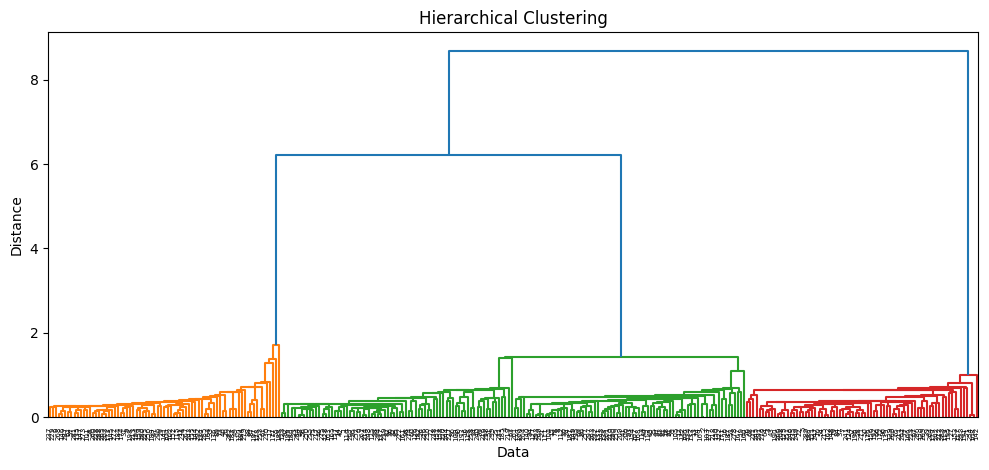

In [4]:
# Data Virtualization (first step)

plt.figure(figsize=(12, 5))

dendrogram(
    hierarchy, orientation="top", distance_sort="descending", show_leaf_counts=True
)

plt.title("Hierarchical Clustering")
plt.xlabel("Data")
plt.ylabel("Distance")
plt.show()

In [5]:
# For method = complete

hierarchy_2 = linkage(X, "complete")

cluster_2 = fcluster(hierarchy_2, 20, criterion="distance")

In [6]:
print("Created cluster number: ", len(np.unique(cluster_2)))

Created cluster number:  2


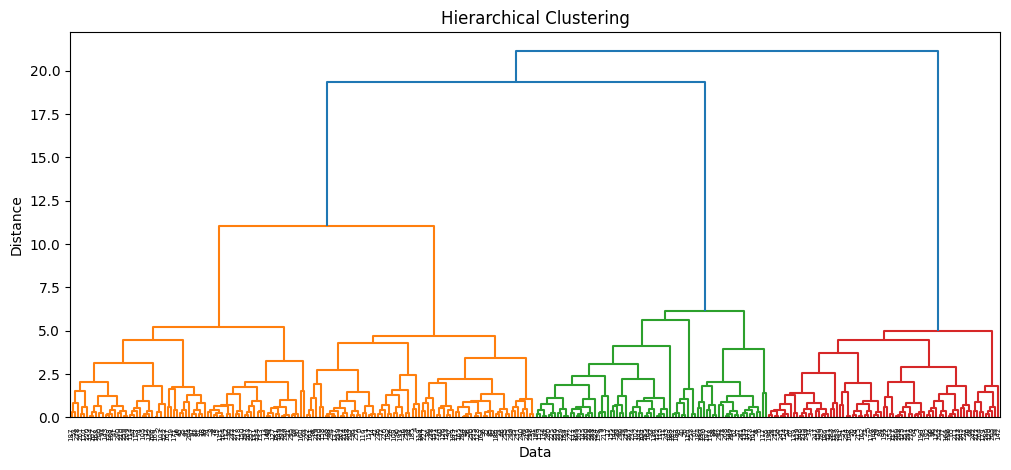

In [7]:
# Data Virtualization

plt.figure(figsize=(12, 5))

dendrogram(
    hierarchy_2, orientation="top", distance_sort="descending", show_leaf_counts=True
)

plt.title("Hierarchical Clustering")
plt.xlabel("Data")
plt.ylabel("Distance")
plt.show()

In [8]:
# For method = complete

hierarchy_3 = linkage(X, "complete")

cluster_3 = fcluster(hierarchy_3, 5, criterion="distance")

In [9]:
print("Created cluster number: ", len(np.unique(cluster_3)))

Created cluster number:  7


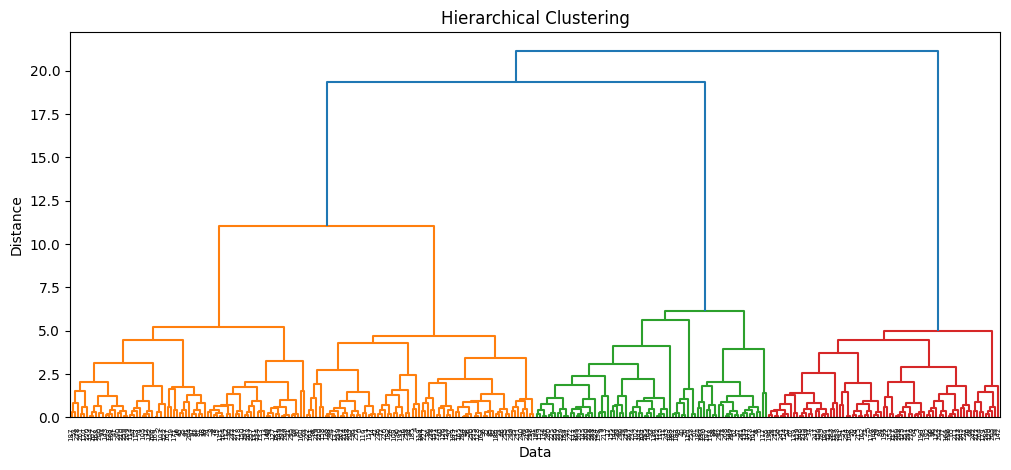

In [10]:
plt.figure(figsize=(12, 5))

dendrogram(
    hierarchy_3, orientation="top", distance_sort="descending", show_leaf_counts=True
)

plt.title("Hierarchical Clustering")
plt.xlabel("Data")
plt.ylabel("Distance")
plt.show()

## Recurrent Neural Network (RNN)

In [11]:
# TOKENIZER SECTION

from keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

In [12]:
data = [
    "This is an example",
    "There is another sentences",
    "Different text here",
    "And finally, the last sentence is here",
]

In [13]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts(data)

numerical_value = tokenizer.texts_to_sequences(data)
print("Word Index: ", tokenizer.word_index)

Word Index:  {'is': 1, 'here': 2, 'this': 3, 'an': 4, 'example': 5, 'there': 6, 'another': 7, 'sentences': 8, 'different': 9, 'text': 10, 'and': 11, 'finally': 12, 'the': 13, 'last': 14, 'sentence': 15}


In [14]:
for line in numerical_value:
    print(line)

[3, 1, 4, 5]
[6, 1, 7, 8]
[9, 10, 2]
[11, 12, 13, 14, 15, 1, 2]


In [15]:
# Determining the maksimum word cout within the numerical_value

print(len(max(numerical_value)))

7


In [16]:
fixed_length = pad_sequences(numerical_value, maxlen=len(max(numerical_value)))

In [17]:
for word in fixed_length:
    print(word)

[0 0 0 3 1 4 5]
[0 0 0 6 1 7 8]
[ 0  0  0  0  9 10  2]
[11 12 13 14 15  1  2]


In [21]:
# EMBEDDING SECTION

import numpy as np
from keras.layers import Embedding

In [20]:
input_dimension = len(tokenizer.word_index) + 1

dimension = 300
embedding_layer = Embedding(
    input_dim=input_dimension, output_dim=dimension, input_length=fixed_length.shape[1]
)

In [22]:
labeled_data = embedding_layer(np.array(fixed_length))

In [23]:
print("Embedding Layer Output Shape:")
print(labeled_data)

Embedding Layer Output Shape:
tf.Tensor(
[[[-0.00798879  0.01085128  0.0156475  ... -0.03053435  0.00200636
    0.03493375]
  [-0.00798879  0.01085128  0.0156475  ... -0.03053435  0.00200636
    0.03493375]
  [-0.00798879  0.01085128  0.0156475  ... -0.03053435  0.00200636
    0.03493375]
  ...
  [ 0.03897392 -0.04349243 -0.03306071 ...  0.04656057  0.00619476
   -0.03917024]
  [-0.00406761  0.03796313  0.00725881 ...  0.04715164 -0.01264747
   -0.04647404]
  [ 0.01319957 -0.03278526  0.03547958 ...  0.02189614 -0.02412959
   -0.00492729]]

 [[-0.00798879  0.01085128  0.0156475  ... -0.03053435  0.00200636
    0.03493375]
  [-0.00798879  0.01085128  0.0156475  ... -0.03053435  0.00200636
    0.03493375]
  [-0.00798879  0.01085128  0.0156475  ... -0.03053435  0.00200636
    0.03493375]
  ...
  [ 0.03897392 -0.04349243 -0.03306071 ...  0.04656057  0.00619476
   -0.03917024]
  [-0.03100705 -0.03620968  0.01312764 ...  0.02139088 -0.01069745
    0.00995002]
  [-0.00290699 -0.03306263  0.04

## RNN

In [25]:
import pandas as pd
from colorama import Fore
from keras.layers import Dense, SimpleRNN
from keras.models import Sequential
from keras.utils import to_categorical
from sklearn.model_selection import train_test_split

In [ ]:
# Importing Dataset
# FOR ONLY GOOGLE COLAB

# from google.colab import drive

# drive.mount("/content/drive")

# data_way = "/content/drive/MyDrive/TechIstanbul/Phishing_Email.csv"

# mail_data = pd.read_csv(data_way)


In [26]:
# Importing Dataset
# FOR IDE

mail_data = pd.read_csv("Phishing_Email.csv")

In [27]:
mail_data = mail_data.where((pd.notnull(mail_data)), "")

In [28]:
mail_data.loc[mail_data["Email Type"] == "Safe Email", "Email Type"] = 0
mail_data.loc[mail_data["Email Type"] == "Phishing Email", "Email Type"] = 1

In [29]:
X = mail_data["Email Text"]
y = mail_data["Email Type"]

In [30]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts(X)
indexed_data = tokenizer.texts_to_sequences(X)

In [31]:
word_index = tokenizer.word_index
word_length = 1000
fixed_length = pad_sequences(indexed_data, maxlen=word_length)

In [32]:
y = to_categorical(y)

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    fixed_length, y, test_size=0.2, random_state=42
)

In [34]:
model = Sequential()
model.add(Embedding(len(word_index) + 1, output_dim=128, input_length=word_length))
model.add(SimpleRNN(64, activation="relu"))
model.add(Dense(2, activation="softmax"))
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

/Users/odoker/.data_env/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [35]:
model.fit(X_train, y_train, epochs=5, batch_size=32, validation_data=(X_test, y_test))

Epoch 1/5
467/467 ━━━━━━━━━━━━━━━━━━━━ 41s 86ms/step - accuracy: 0.8450 - loss: 49835604443136.0000 - val_accuracy: 0.4952 - val_loss: 32271064.0000
Epoch 2/5
467/467 ━━━━━━━━━━━━━━━━━━━━ 40s 86ms/step - accuracy: 0.8574 - loss: 200320.0781 - val_accuracy: 0.8823 - val_loss: 0.5406
Epoch 3/5
467/467 ━━━━━━━━━━━━━━━━━━━━ 40s 86ms/step - accuracy: 0.9334 - loss: 0.2318 - val_accuracy: 0.9038 - val_loss: 0.4421
Epoch 4/5
467/467 ━━━━━━━━━━━━━━━━━━━━ 40s 86ms/step - accuracy: 0.9531 - loss: 0.1445 - val_accuracy: 0.9131 - val_loss: 0.3963
Epoch 5/5
467/467 ━━━━━━━━━━━━━━━━━━━━ 40s 86ms/step - accuracy: 0.9628 - loss: 0.1081 - val_accuracy: 0.9172 - val_loss: 0.3695


In [36]:
model.save("rnn.keras")

In [37]:
import tensorflow as tf

model = tf.keras.models.load_model("rnn.keras", compile=False)

# Remove the compile parameter when training and execute the following.
# model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [38]:
while True:
    inputted_email = input("Please enter your email message:  ")
    if inputted_email == "quit":
        break
    inputted_email_tok = tokenizer.texts_to_sequences([inputted_email])
    fixed_length = pad_sequences(inputted_email_tok, maxlen=word_length)

    prediction = model.predict(fixed_length)
    if np.argmax(prediction) == 1:
        print(Fore.RED, "This is a Phishing email")
    else:
        print(Fore.GREEN, "This is not a Phishing email")
    print(Fore.BLUE, "Accuracy Score: ", prediction[0][np.argmax(prediction)])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
 This is not a Phishing email
 Accuracy Score:  0.81920654
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
 This is not a Phishing email
 Accuracy Score:  0.81920654
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
 This is not a Phishing email
 Accuracy Score:  0.81920654


### Phishing Email Example
gino , who do u want to win ? the secret on how porn stars grew big dicks ! the answer is here . turn off notifications here . wv international exports ltd st . nathaniel # 4780 belize city , belize

<br><br>

### Safe Email Example
open season notices as today is the deadline for our open season responses , please make a copy of any capacity requests for me as i will consolidate them and send out a summary to the commercial group . thanks . lorraine